In [1]:
import os
import numpy as np
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from sklearn.utils import shuffle
import pandas as pd

In [9]:

class_names = ['biryani','chapati','corn','fried_rice','jalebi','mango','watermelon']
class_names_label = {class_name: i for i, class_name in enumerate(class_names)}
nb_classes = len(class_names)

IMAGE_SIZE = (150, 150)
BATCH_SIZE = 32

In [10]:

transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [11]:

train_dataset = datasets.ImageFolder(root=r"train", transform=transform)
test_dataset = datasets.ImageFolder(root=r"train", transform=transform)


In [12]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [13]:

n_train = len(train_dataset)
n_test = len(test_dataset)

print(f"Number of training examples: {n_train}")
print(f"Number of testing examples: {n_test}")
print(f"Each image is of size: {IMAGE_SIZE}")

Number of training examples: 899
Number of testing examples: 899
Each image is of size: (150, 150)


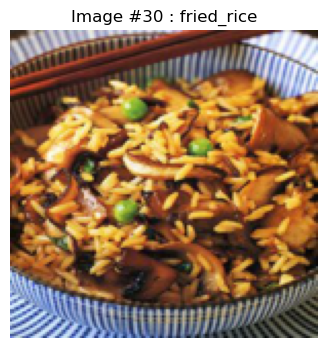

In [14]:
import matplotlib.pyplot as plt
import numpy as np

dataiter = iter(train_loader)
images, labels = next(dataiter)

index = np.random.randint(len(labels))


image = images[index].numpy().transpose(1, 2, 0)  # C,H,W -> H,W,C
label = labels[index].item()


mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
image = image * std + mean
image = np.clip(image, 0, 1)


plt.figure(figsize=(4,4))
plt.imshow(image)
plt.axis('off')
plt.title(f'Image #{index} : {class_names[label]}')
plt.show()


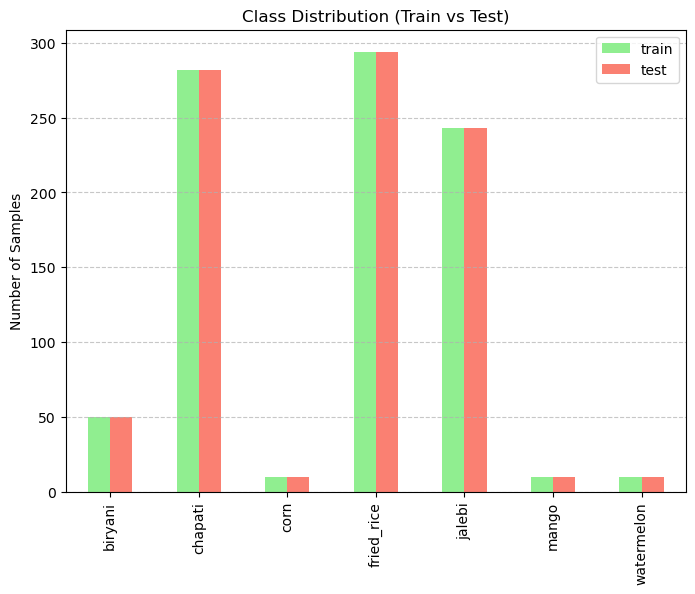

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_dataset_distribution(train_dataset, test_dataset, class_names,
                              graph_type='bar', colors=('skyblue', 'orange')):

    train_labels = [label for _, label in train_dataset]
    test_labels = [label for _, label in test_dataset]

   
    _, train_counts = np.unique(train_labels, return_counts=True)
    _, test_counts = np.unique(test_labels, return_counts=True)

  
    df_counts = pd.DataFrame({'train': train_counts, 'test': test_counts}, index=class_names)

   
    if graph_type == 'bar':
        df_counts.plot(kind='bar', color=colors, figsize=(8,6))
        plt.ylabel('Number of Samples')
        plt.title('Class Distribution (Train vs Test)')
    elif graph_type == 'barh':
        df_counts.plot(kind='barh', color=colors, figsize=(8,6))
        plt.xlabel('Number of Samples')
        plt.title('Class Distribution (Train vs Test)')
    elif graph_type == 'pie':
        # For pie, show train and test separately
        plt.figure(figsize=(12,5))
        plt.subplot(1,2,1)
        plt.pie(train_counts, labels=class_names, autopct='%1.1f%%', colors=plt.cm.tab20.colors)
        plt.title('Train Set Distribution')
        plt.subplot(1,2,2)
        plt.pie(test_counts, labels=class_names, autopct='%1.1f%%', colors=plt.cm.tab20c.colors)
        plt.title('Test Set Distribution')
    else:
        raise ValueError("graph_type must be 'bar', 'barh', or 'pie'")

    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()


plot_dataset_distribution(train_dataset, test_dataset, class_names,
                          graph_type='bar', colors=('lightgreen', 'salmon'))


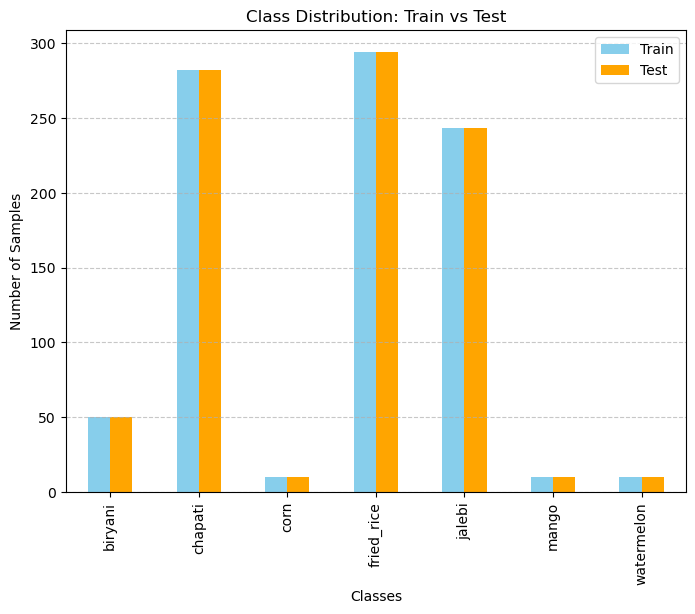

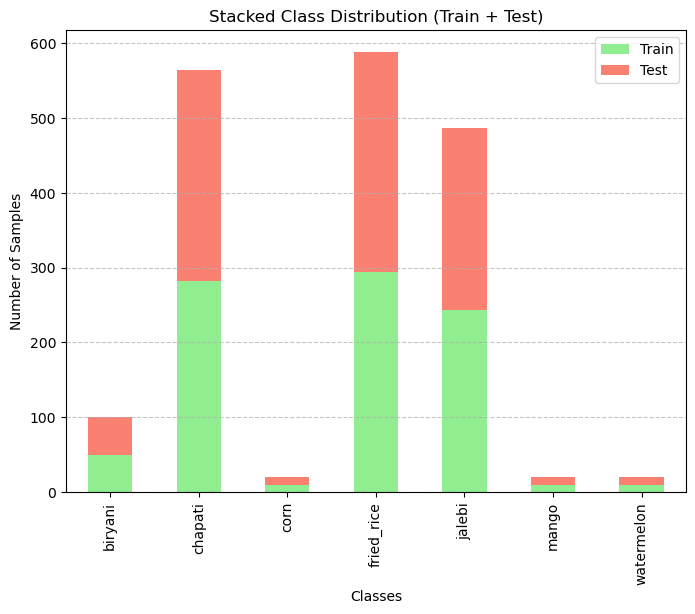

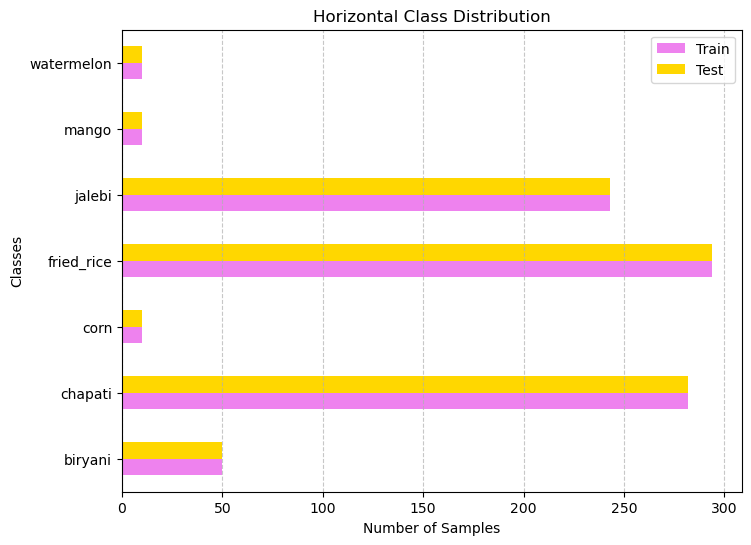

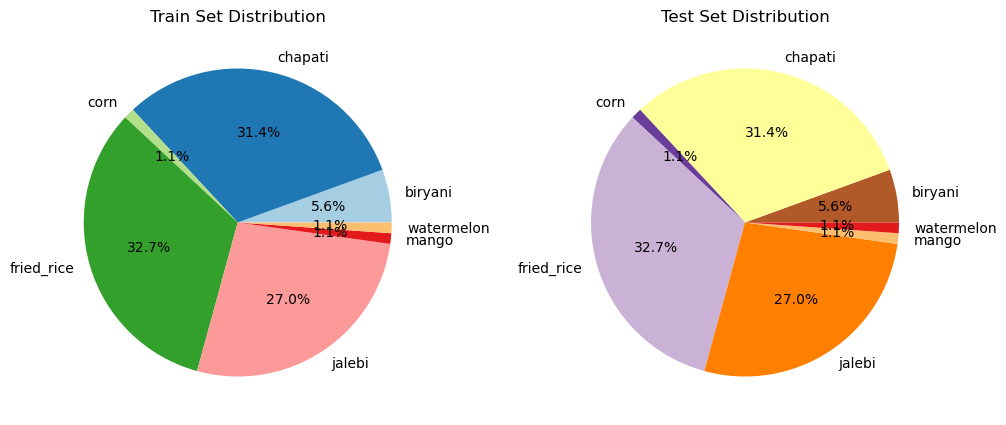

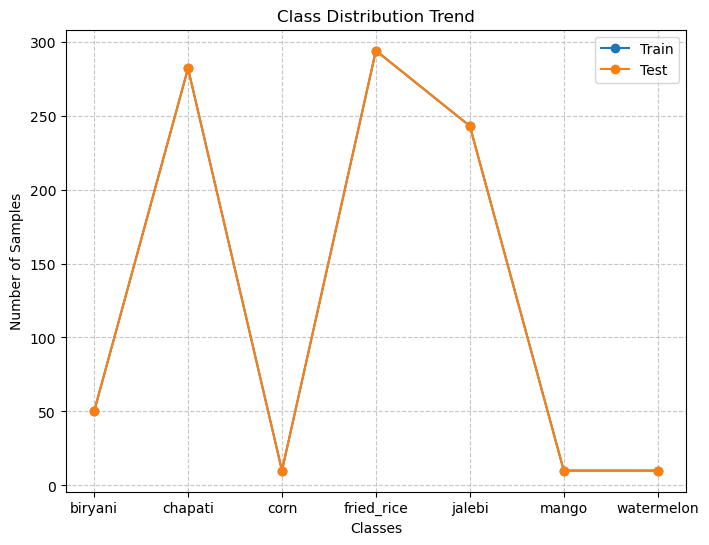

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


train_labels = [label for _, label in train_dataset]
test_labels = [label for _, label in test_dataset]

_, train_counts = np.unique(train_labels, return_counts=True)
_, test_counts = np.unique(test_labels, return_counts=True)


df_counts = pd.DataFrame({'Train': train_counts, 'Test': test_counts}, index=class_names)


df_counts.plot(kind='bar', figsize=(8,6), color=['skyblue', 'orange'])
plt.title('Class Distribution: Train vs Test')
plt.ylabel('Number of Samples')
plt.xlabel('Classes')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


df_counts.plot(kind='bar', stacked=True, figsize=(8,6), color=['lightgreen', 'salmon'])
plt.title('Stacked Class Distribution (Train + Test)')
plt.ylabel('Number of Samples')
plt.xlabel('Classes')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


df_counts.plot(kind='barh', figsize=(8,6), color=['violet', 'gold'])
plt.title('Horizontal Class Distribution')
plt.xlabel('Number of Samples')
plt.ylabel('Classes')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.pie(train_counts, labels=class_names, autopct='%1.1f%%', colors=plt.cm.Paired.colors)
plt.title('Train Set Distribution')

plt.subplot(1,2,2)
plt.pie(test_counts, labels=class_names, autopct='%1.1f%%', colors=plt.cm.Paired_r.colors)
plt.title('Test Set Distribution')

plt.show()


df_counts.plot(kind='line', marker='o', figsize=(8,6))
plt.title('Class Distribution Trend')
plt.ylabel('Number of Samples')
plt.xlabel('Classes')
plt.grid(linestyle='--', alpha=0.7)
plt.show()


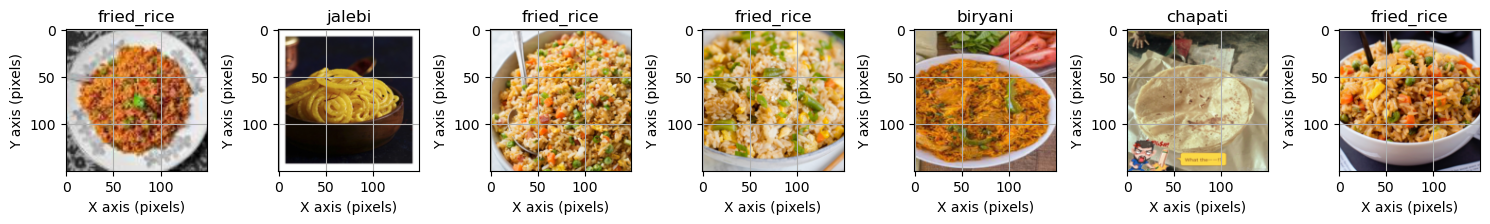

In [16]:
import matplotlib.pyplot as plt
import numpy as np


num_examples = 7


dataiter = iter(train_loader)
images, labels = next(dataiter)


plt.figure(figsize=(15, 5))  # width, height

for i in range(num_examples):
    plt.subplot(1, num_examples, i + 1)  # 1 row, num_examples columns
    plt.grid(True)
    
   
    image = images[i].numpy().transpose(1, 2, 0)
    

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    image = image * std + mean
    image = np.clip(image, 0, 1)
    
    plt.imshow(image)
    
  
    plt.xlabel(f'X axis (pixels)')
    plt.ylabel(f'Y axis (pixels)')
    
   
    plt.title(class_names[labels[i].item()])

plt.tight_layout()
plt.show()


In [17]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchvision.utils import save_image
import os



In [18]:


class Classifier(nn.Module):
    def __init__(self, num_classes):
        super(Classifier, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, 1, 1)
        self.conv2 = nn.Conv2d(32, 64, 3, 1, 1)
        self.fc1 = nn.Linear(64 * 37 * 37, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = torch.max_pool2d(x, 2, 2)
        x = torch.relu(self.conv2(x))
        x = torch.max_pool2d(x, 2, 2)
        x = torch.flatten(x, 1)
        x = torch.relu(self.fc1(x))
        return self.fc2(x)


class Generator(nn.Module):
    def __init__(self, nz, num_classes):
        super(Generator, self).__init__()
        self.label_emb = nn.Embedding(num_classes, num_classes)

        self.model = nn.Sequential(
            nn.Linear(nz + num_classes, 256),
            nn.ReLU(True),
            nn.Linear(256, 512),
            nn.ReLU(True),
            nn.Linear(512, 1024),
            nn.ReLU(True),
            nn.Linear(1024, 3 * 150 * 150),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        c = self.label_emb(labels)
        x = torch.cat([noise, c], dim=1)
        img = self.model(x)
        img = img.view(img.size(0), 3, 150, 150)
        return img

class Discriminator(nn.Module):
    def __init__(self, num_classes):
        super(Discriminator, self).__init__()
        self.label_emb = nn.Embedding(num_classes, num_classes)

        self.model = nn.Sequential(
            nn.Linear(3 * 150 * 150 + num_classes, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 1),
            nn.Sigmoid(),
        )

    def forward(self, img, labels):
        img_flat = img.view(img.size(0), -1)
        c = self.label_emb(labels)
        x = torch.cat([img_flat, c], dim=1)
        return self.model(x)


In [19]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [20]:
transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

train_dataset = datasets.ImageFolder(
    r"train",
    transform=transform
)

test_dataset = datasets.ImageFolder(
    r"test",
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

num_classes = len(train_dataset.classes)



In [21]:
nz = 100

generator = Generator(nz, num_classes).to(device)
discriminator = Discriminator(num_classes).to(device)

criterion_gan = nn.BCELoss()
optimizer_G = optim.Adam(generator.parameters(), lr=0.0002)
optimizer_D = optim.Adam(discriminator.parameters(), lr=0.0002)




In [22]:
epochs_gan = 20
os.makedirs("generated_images", exist_ok=True)

for epoch in range(epochs_gan):
    for real_imgs, labels in train_loader:
        real_imgs, labels = real_imgs.to(device), labels.to(device)
        batch = real_imgs.size(0)

        # ---- Train Discriminator ----
        noise = torch.randn(batch, nz).to(device)
        fake_imgs = generator(noise, labels)

        real_validity = discriminator(real_imgs, labels)
        fake_validity = discriminator(fake_imgs.detach(), labels)

        d_loss = (criterion_gan(real_validity, torch.ones_like(real_validity)) +
                  criterion_gan(fake_validity, torch.zeros_like(fake_validity))) / 2

        optimizer_D.zero_grad()
        d_loss.backward()
        optimizer_D.step()

        # ---- Train Generator ----
        fake_validity = discriminator(fake_imgs, labels)
        g_loss = criterion_gan(fake_validity, torch.ones_like(fake_validity))

        optimizer_G.zero_grad()
        g_loss.backward()
        optimizer_G.step()

    print(f"Epoch {epoch+1}/{epochs_gan} | D Loss: {d_loss:.3f} | G Loss: {g_loss:.3f}")

    save_image(fake_imgs[:25], f"generated_images/epoch_{epoch+1}.png", nrow=5)


Epoch 1/20 | D Loss: 0.175 | G Loss: 1.950
Epoch 2/20 | D Loss: 0.025 | G Loss: 3.253
Epoch 3/20 | D Loss: 0.065 | G Loss: 2.707
Epoch 4/20 | D Loss: 0.065 | G Loss: 3.127
Epoch 5/20 | D Loss: 0.260 | G Loss: 1.236
Epoch 6/20 | D Loss: 0.057 | G Loss: 4.392
Epoch 7/20 | D Loss: 0.118 | G Loss: 2.391
Epoch 8/20 | D Loss: 0.403 | G Loss: 0.990
Epoch 9/20 | D Loss: 0.409 | G Loss: 1.879
Epoch 10/20 | D Loss: 0.076 | G Loss: 4.427
Epoch 11/20 | D Loss: 0.187 | G Loss: 1.860
Epoch 12/20 | D Loss: 0.128 | G Loss: 2.539
Epoch 13/20 | D Loss: 0.028 | G Loss: 3.750
Epoch 14/20 | D Loss: 0.135 | G Loss: 2.764
Epoch 15/20 | D Loss: 0.123 | G Loss: 2.223
Epoch 16/20 | D Loss: 0.038 | G Loss: 5.593
Epoch 17/20 | D Loss: 8.705 | G Loss: 2.195
Epoch 18/20 | D Loss: 7.855 | G Loss: 4.823
Epoch 19/20 | D Loss: 15.891 | G Loss: 3.569
Epoch 20/20 | D Loss: 0.006 | G Loss: 9.011


In [23]:
classification_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

classifier = Classifier(num_classes).to(device)
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = optim.Adam(classifier.parameters(), lr=0.001)

In [26]:
epochs_cls = 20



for epoch in range(epochs_cls):
    classifier.train()
    running_loss = 0

    for real_imgs, labels in train_loader:
        real_imgs, labels = real_imgs.to(device), labels.to(device)

     
        noise = torch.randn(real_imgs.size(0), nz).to(device)
        gan_imgs = generator(noise, labels).detach()
 
      
        combined_imgs = torch.cat([real_imgs, gan_imgs], dim=0)
        combined_labels = torch.cat([labels, labels], dim=0)

        outputs = classifier(combined_imgs)
        loss = criterion_cls(outputs, combined_labels)

        optimizer_cls.zero_grad()
        loss.backward()
        optimizer_cls.step()

        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs_cls}]  Loss: {running_loss:.4f}")



Epoch [1/20]  Loss: 47.2401
Epoch [2/20]  Loss: 35.7219
Epoch [3/20]  Loss: 32.0469
Epoch [4/20]  Loss: 29.6137
Epoch [5/20]  Loss: 26.3694
Epoch [6/20]  Loss: 25.2023
Epoch [7/20]  Loss: 22.7873
Epoch [8/20]  Loss: 20.9073
Epoch [9/20]  Loss: 21.1582
Epoch [10/20]  Loss: 19.3301
Epoch [11/20]  Loss: 18.8123
Epoch [12/20]  Loss: 18.3921
Epoch [13/20]  Loss: 18.7088
Epoch [14/20]  Loss: 18.6722
Epoch [15/20]  Loss: 18.1894
Epoch [16/20]  Loss: 18.4336
Epoch [17/20]  Loss: 18.0547
Epoch [18/20]  Loss: 17.7797
Epoch [19/20]  Loss: 17.9385
Epoch [20/20]  Loss: 18.8042


In [27]:
torch.save(classifier.state_dict(), "classifier.pth")
torch.save(generator.state_dict(), "generator.pth")
torch.save(discriminator.state_dict(), "discriminator.pth")


In [1]:
from flask import Flask, render_template, request, redirect, session
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import os

app = Flask(__name__)
app.secret_key = "secret_key"

# ================= IMAGE TRANSFORM =================
transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# ================= CNN MODEL =================
class YourModelClass(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self._to_linear = self._get_size()
        self.fc1 = nn.Linear(self._to_linear, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def _get_size(self):
        x = torch.zeros(1, 3, 150, 150)
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        return x.view(1, -1).size(1)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# ================= LOAD MODEL =================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_names = ['biryani', 'chapati', 'corn', 'fried_rice', 'jalebi', 'mango', 'watermelon']

model = YourModelClass(len(class_names))
model.load_state_dict(torch.load("classifier.pth", map_location=device))
model.to(device)
model.eval()

# ================= NUTRITION DATA (SAFE) =================
nutrition_data = {
     "biryani": {
        "Calories": "300–350 kcal",
        "Protein": "16 g",
        "Carbs": "35 g",
        "Fat": "12 g",
        "Vitamins": ["Vitamin B6", "Vitamin B12"],
        "Minerals": ["Iron", "Zinc"],
        "Iron": "2.5 mg",
        "Calcium": "40 mg",
        "Magnesium": "35 mg",
        "Potassium": "220 mg",
        "Best_Time": "Lunch",
        "Good_For": ["Energy", "Muscle strength"],
        "Helps_Reduce": ["Weakness"],
        "Benefits": ["High energy", "Protein rich"],
        "Disadvantages": ["High calories", "High fat"],
        "Avoid": "Heart patients, obesity",
        "Suggestion": "Eat occasionally, avoid excess oil."
    },
    "chapati": {
        "Calories": "100 kcal",
        "Protein": "3 g",
        "Carbs": "18 g",
        "Fat": "0.4 g",
        "Vitamins": ["Vitamin B1"],
        "Minerals": ["Iron", "Magnesium"],
        "Iron": "1 mg",
        "Calcium": "20 mg",
        "Magnesium": "25 mg",
        "Potassium": "120 mg",
        "Best_Time": "Lunch / Dinner",
        "Good_For": ["Digestion"],
        "Helps_Reduce": ["Constipation"],
        "Benefits": ["High fiber"],
        "Disadvantages": ["Low protein alone"],
        "Avoid": "Gluten intolerance",
        "Suggestion": "Eat with vegetables."
    },
    "corn": {
        "Calories": "96 kcal",
        "Protein": "3 g",
        "Carbs": "21 g",
        "Fat": "1.5 g",
        "Vitamins": ["Vitamin B5", "Vitamin C"],
        "Minerals": ["Magnesium", "Phosphorus"],
        "Iron": "0.5 mg",
        "Calcium": "7 mg",
        "Magnesium": "37 mg",
        "Potassium": "270 mg",
        "Best_Time": "Morning",
        "Good_For": ["Digestion"],
        "Helps_Reduce": ["Constipation"],
        "Benefits": ["Fiber rich"],
        "Disadvantages": ["High starch"],
        "Avoid": "Diabetics (excess)",
        "Suggestion": "Prefer boiled corn."
    },

    "fried_rice": {
        "Calories": "250 kcal",
        "Protein": "5 g",
        "Carbs": "40 g",
        "Fat": "7 g",
        "Vitamins": ["Vitamin B1", "Vitamin B3"],
        "Minerals": ["Iron", "Magnesium"],
        "Iron": "1.8 mg",
        "Calcium": "30 mg",
        "Magnesium": "32 mg",
        "Potassium": "180 mg",
        "Best_Time": "Lunch",
        "Good_For": ["Energy"],
        "Helps_Reduce": ["Low energy"],
        "Benefits": ["Quick energy"],
        "Disadvantages": ["High oil", "Low fiber"],
        "Avoid": "Diabetes, obesity",
        "Suggestion": "Use brown rice and less oil."
    },

    "jalebi": {
        "Calories": "200 kcal",
        "Protein": "1 g",
        "Carbs": "30 g",
        "Fat": "8 g",
        "Vitamins": ["Vitamin B1"],
        "Minerals": ["Iron"],
        "Iron": "1.2 mg",
        "Calcium": "20 mg",
        "Magnesium": "15 mg",
        "Potassium": "90 mg",
        "Best_Time": "Occasional",
        "Good_For": ["Instant energy"],
        "Helps_Reduce": [],
        "Benefits": ["Quick sugar boost"],
        "Disadvantages": ["Very high sugar"],
        "Avoid": "Diabetics",
        "Suggestion": "Eat rarely, small quantity."
    },
        "mango": {
        "Calories": "99 kcal",
        "Protein": "1.4 g",
        "Carbs": "25 g",
        "Fat": "0.6 g",
        "Vitamins": ["Vitamin A", "Vitamin C"],
        "Minerals": ["Potassium"],
        "Iron": "0.2 mg",
        "Calcium": "11 mg",
        "Magnesium": "10 mg",
        "Potassium": "168 mg",
        "Best_Time": "Morning",
        "Good_For": ["Skin", "Immunity"],
        "Helps_Reduce": ["Vitamin deficiency"],
        "Benefits": ["Boosts immunity"],
        "Disadvantages": ["High sugar"],
        "Avoid": "Diabetics",
        "Suggestion": "Limit intake."
    },

    "watermelon": {
        "Calories": "30 kcal",
        "Protein": "0.6 g",
        "Carbs": "8 g",
        "Fat": "0.2 g",
        "Vitamins": ["Vitamin A", "Vitamin C"],
        "Minerals": ["Potassium"],
        "Iron": "0.4 mg",
        "Calcium": "7 mg",
        "Magnesium": "10 mg",
        "Potassium": "112 mg",
        "Best_Time": "Morning / Afternoon",
        "Good_For": ["Hydration"],
        "Helps_Reduce": ["Dehydration"],
        "Benefits": ["Low calorie"],
        "Disadvantages": ["Low fiber"],
        "Avoid": "Kidney patients",
        "Suggestion": "Eat fresh."
    }
}

# ================= PREDICTION =================
def predict_image(image_path):
    img = Image.open(image_path).convert("RGB")
    tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(tensor)
        _, predicted = torch.max(outputs, 1)

    cls = class_names[predicted.item()]
    nutrition = nutrition_data.get(cls, {})

    # DEFAULT SAFE FIELDS
    defaults = {
        "Vitamins": [],
        "Minerals": [],
        "Iron": "N/A",
        "Calcium": "N/A",
        "Magnesium": "N/A",
        "Potassium": "N/A",
        "Best_Time": "Not specified",
        "Good_For": [],
        "Helps_Reduce": [],
        "Benefits": [],
        "Disadvantages": [],
        "Avoid": "N/A",
        "Suggestion": "N/A"
    }

    for k, v in defaults.items():
        nutrition.setdefault(k, v)

    return cls, nutrition

# ================= ROUTES =================
users = {}

@app.route('/', methods=['GET', 'POST'])
def signin():
    if request.method == 'POST':
        users[request.form['username']] = request.form['password']
        session['username'] = request.form['username']
        return redirect('/home')
    return render_template('signin.html')
@app.route('/signup', methods=['GET', 'POST'])
def signup():
    if request.method == 'POST':
        username = request.form['username']
        password = request.form['password']

        # prevent duplicate users
        if username in users:
            return "User already exists!"

        users[username] = password
        return redirect('/')

    return render_template('signup.html')



@app.route('/home')
def home():
    return render_template('home.html')

@app.route('/detection', methods=['GET', 'POST'])
def detection():
    if request.method == 'POST':
        img = request.files['image']
        path = os.path.join("static", img.filename)
        img.save(path)

        predicted_class, nutrition = predict_image(path)
        return render_template(
            "detection.html",
            predicted_class=predicted_class,
            nutrition=nutrition,
            image_path=path
        )

    return render_template("detection.html")

if __name__ == "__main__":
    app.run(debug=True, use_reloader=False)



 * Serving Flask app '__main__'
 * Debug mode: on


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
127.0.0.1 - - [21/Oct/2026 13:29:46] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [21/Oct/2026 13:29:46] "GET /static/inp2.png HTTP/1.1" 200 -
127.0.0.1 - - [21/Oct/2026 13:29:46] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [21/Oct/2026 13:29:49] "POST / HTTP/1.1" 302 -
127.0.0.1 - - [21/Oct/2026 13:29:49] "GET /home HTTP/1.1" 200 -
127.0.0.1 - - [21/Oct/2026 13:29:49] "GET /static/inp.png HTTP/1.1" 200 -
127.0.0.1 - - [21/Oct/2026 13:29:51] "GET /detection HTTP/1.1" 200 -
127.0.0.1 - - [21/Oct/2026 13:30:17] "POST /detection HTTP/1.1" 200 -
127.0.0.1 - - [21/Oct/2026 13:30:17] "GET /static/Image_8.jpg HTTP/1.1" 200 -
